<a href="https://colab.research.google.com/github/Kamal-Minocha/10_Days_of_App_Dev/blob/master/assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import random
import re
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

ROLL_NUMBER = "1024170188"

# Standard template representing the starter notebook dataset generator
def generate_dataset(roll_no):
    random.seed(int(roll_no))

    templates = [
        "Dear support, our Wi-Fi isn't working at the office. Please check the router. Contact me at support-team@company.com or +1-555-0199. System version is 2.0.1.",
        "Error 95.5 received during database connection. Please help ASAP! More details at https://status.database.io/errors.",
        "The state-of-the-art printer isn't printing double-sided pages. Please update its driver software.",
        "User complaining about slow internet. I checked, the connection is active but slow. Contact admin at admin@net.com.",
        "The server is throwing a 500 Internal Error. Please restart service at http://127.0.0.1/status immediately.",
        "We need an upgrade for the system. Current version is 1.4.3. Contact coordinator at +91-9876543210.",
        "I can't access my email account. It says password incorrect. Please reset my credentials.",
        "Our VPN is disconnecting frequently. Is anyone else facing this issue? Check logs at https://vpn.secure-tunnel.org/log.",
        "The application crashes whenever we open a large file. We are using version 5.0.1 on Windows 11.",
        "Please install the new anti-virus software on all lab PCs. It's urgent.",
        "My laptop screen keeps flickering. Is it a hardware issue or a graphic card driver issue?",
        "The backup process failed last night. Error code: 99.9. Please resolve this at backup-admin@enterprise.org.",
        "Can we schedule a maintenance window for the core switches this Saturday?",
        "The office projector isn't displaying colors correctly. It looks very blurry."
    ]

    # Select a random subset between 12 and 16 tickets
    num_tickets = random.randint(12, 16)
    tickets = random.sample(templates, min(num_tickets, len(templates)))

    # Generate a simple deterministic 8-character fingerprint
    fingerprint = f"{hash(roll_no) & 0xffffffff:08x}"

    return tickets, fingerprint

raw_tickets, fingerprint = generate_dataset(ROLL_NUMBER)
print(f"Generated {len(raw_tickets)} tickets.")
print(f"Fingerprint: {fingerprint}")

Generated 14 tickets.
Fingerprint: 397e695f


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


In [ ]:
def process_ticket(ticket):
    # Basic text cleaning representing standard starter processing
    cleaned = ticket.lower()
    # Tokenize
    tokens = word_tokenize(cleaned)
    # Filter out stopwords and punctuation for final tokens
    stop_words = set(stopwords.words('english'))
    final_tokens = [t for t in tokens if t.isalnum() and t not in stop_words]
    return {
        'raw': ticket,
        'tokens': tokens,
        'final_tokens': final_tokens
    }

processed_tickets = [process_ticket(t) for t in raw_tickets]
print(f"Successfully processed {len(processed_tickets)} tickets!")

Successfully processed 14 tickets!


### Question 1: Preprocessing Table

In [ ]:
import string

stop_words = set(stopwords.words('english'))
punct_set = set(string.punctuation)

stats_data = []
for idx, t in enumerate(processed_tickets):
    raw = t['raw']
    tokens = t['tokens']
    final = t['final_tokens']

    # Sentences count
    num_sentences = len(nltk.sent_tokenize(raw))
    # Total tokens
    num_tokens = len(tokens)
    # Punctuation count
    num_punct = sum(1 for tok in tokens if all(char in punct_set for char in tok))
    # Stopwords count
    num_stop = sum(1 for tok in tokens if tok in stop_words)
    # Unique tokens
    num_unique = len(set(tokens))
    # Final tokens
    num_final = len(final)

    stats_data.append({
        'Ticket': f"Ticket {idx+1}",
        'Sentences': num_sentences,
        'Tokens': num_tokens,
        'Punctuation': num_punct,
        'Stopwords': num_stop,
        'Unique': num_unique,
        'Final': num_final
    })

df_stats = pd.DataFrame(stats_data)

# Create Total Row
total_row = pd.Series({
    'Ticket': 'TOTAL',
    'Sentences': df_stats['Sentences'].sum(),
    'Tokens': df_stats['Tokens'].sum(),
    'Punctuation': df_stats['Punctuation'].sum(),
    'Stopwords': df_stats['Stopwords'].sum(),
    'Unique': df_stats['Unique'].sum(),
    'Final': df_stats['Final'].sum()
})

df_stats = pd.concat([df_stats, pd.DataFrame([total_row])], ignore_index=True)
display(df_stats)

,Ticket,Sentences,Tokens,Punctuation,Stopwords,Unique,Final
0,Ticket 1,2,14,2,4,13,7
1,Ticket 2,3,17,2,6,16,7
2,Ticket 3,4,31,6,9,25,10
3,Ticket 4,2,18,3,4,17,10
4,Ticket 5,1,13,1,6,13,6
5,Ticket 6,3,19,4,3,18,9
6,Ticket 7,2,15,2,3,14,7
7,Ticket 8,3,18,4,3,17,9
8,Ticket 9,2,19,2,6,17,10
9,Ticket 10,3,18,3,4,15,10


In [ ]:
# Detailed token breakdown for Ticket 1
selected_ticket = processed_tickets[0]
tokens_1 = selected_ticket['tokens']

punct_tokens_1 = [tok for tok in tokens_1 if all(char in punct_set for char in tok)]
stop_tokens_1 = [tok for tok in tokens_1 if tok in stop_words]
final_tokens_1 = selected_ticket['final_tokens']

print("--- Detailed Token Analysis for Ticket 1 ---")
print("Raw Text:", selected_ticket['raw'])
print("\nActual Tokens:", tokens_1)
print("\nPunctuation Tokens:", punct_tokens_1)
print("\nStopwords:", stop_tokens_1)
print("\nFinal Tokens:", final_tokens_1)

--- Detailed Token Analysis for Ticket 1 ---
Raw Text: The office projector isn't displaying colors correctly. It looks very blurry.

Actual Tokens: ['the', 'office', 'projector', 'is', "n't", 'displaying', 'colors', 'correctly', '.', 'it', 'looks', 'very', 'blurry', '.']

Punctuation Tokens: ['.', '.']

Stopwords: ['the', 'is', 'it', 'very']

Final Tokens: ['office', 'projector', 'displaying', 'colors', 'correctly', 'looks', 'blurry']


### Question 2: Regex Extraction & Replacement

In [ ]:
TEST_LINES = [
    "Contact support-team@company.com or support@company.org.in for info.",
    "Visit https://status.database.io/errors or http://localhost:8080.",
    "Reach me at +1-555-0199 or +91-9876543210.",
    "The application isn't working on Wi-Fi state-of-the-art version 2.0.1 or 95.5."
]

print("--- Regex Extraction Patterns ---")
for line in TEST_LINES:
    print(f"\nLine: {line}")
    # Words longer than 5 letters
    words_longer_5 = re.findall(r'\b[a-zA-Z]{6,}\b', line)
    # Numbers with decimals and version numbers
    numbers = re.findall(r'\b\d+(?:\.\d+)+\b|\b\d+\b', line)
    # Capitalized words
    cap_words = re.findall(r'\b[A-Z][a-zA-Z]*\b', line)
    # Words beginning with a vowel
    vowel_words = re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', line)

    print("Words > 5 chars:", words_longer_5)
    print("Numbers / Versions:", numbers)
    print("Capitalized:", cap_words)
    print("Starts with Vowel:", vowel_words)

print("\n--- Regex Replacement Patterns ---")
email_pattern = r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}'
url_pattern = r'https?://[^\s]+'
phone_pattern = r'\+?\d{1,4}[-\s]?\d{3,5}[-\s]?\d{4}'

for line in TEST_LINES:
    substituted = re.sub(email_pattern, '<EMAIL>', line)
    substituted = re.sub(url_pattern, '<URL>', substituted)
    substituted = re.sub(phone_pattern, '<PHONE>', substituted)
    print(f"Original: {line}")
    print(f"Replaced: {substituted}\n")


--- Regex Extraction Patterns ---

Line: Contact support-team@company.com or support@company.org.in for info.
Words > 5 chars: ['Contact', 'support', 'company', 'support', 'company']
Numbers / Versions: []
Capitalized: ['Contact']
Starts with Vowel: ['or', 'org', 'in', 'info']

Line: Visit https://status.database.io/errors or http://localhost:8080.
Words > 5 chars: ['status', 'database', 'errors', 'localhost']
Numbers / Versions: ['8080']
Capitalized: ['Visit']
Starts with Vowel: ['io', 'errors', 'or']

Line: Reach me at +1-555-0199 or +91-9876543210.
Words > 5 chars: []
Numbers / Versions: ['1', '555', '0199', '91', '9876543210']
Capitalized: ['Reach']
Starts with Vowel: ['at', 'or']

Line: The application isn't working on Wi-Fi state-of-the-art version 2.0.1 or 95.5.
Words > 5 chars: ['application', 'working', 'version']
Numbers / Versions: ['2.0.1', '95.5']
Capitalized: ['The', 'Wi', 'Fi']
Starts with Vowel: ['application', 'isn', 'on', 'of', 'art', 'or']

--- Regex Replacement Patt

### Question 3: Custom Tokenization

In [ ]:
from nltk.tokenize import RegexpTokenizer

# Compound pattern
pattern = r'''(?x)
    [a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}
    | https?://[^\s]+
    | \+?\d{1,4}[-\s]?\d{3,5}[-\s]?\d{4}
    | \b\d+(?:\.\d+)+\b
    | \b\w+(?:-\w+)*\b
    | \b\w+['’]\w+\b
'''

custom_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("--- Custom Tokenization Test ---")
for line in TEST_LINES:
    print(f"\nLine: {line}")
    print("Custom Tokenizer:", my_tokenize(line))
    try:
        print("NLTK Word Tokenizer:", word_tokenize(line))
    except Exception as e:
        print("NLTK Word Tokenizer Error:", e)


--- Custom Tokenization Test ---

Line: Contact support-team@company.com or support@company.org.in for info.
Custom Tokenizer: ['Contact', 'support-team@company.com', 'or', 'support@company.org.in', 'for', 'info']
NLTK Word Tokenizer: ['Contact', 'support-team', '@', 'company.com', 'or', 'support', '@', 'company.org.in', 'for', 'info', '.']

Line: Visit https://status.database.io/errors or http://localhost:8080.
Custom Tokenizer: ['Visit', 'https://status.database.io/errors', 'or', 'http://localhost:8080.']
NLTK Word Tokenizer: ['Visit', 'https', ':', '//status.database.io/errors', 'or', 'http', ':', '//localhost:8080', '.']

Line: Reach me at +1-555-0199 or +91-9876543210.
Custom Tokenizer: ['Reach', 'me', 'at', '+1-555-0199', 'or', '+91-987654321']
NLTK Word Tokenizer: ['Reach', 'me', 'at', '+1-555-0199', 'or', '+91-9876543210', '.']

Line: The application isn't working on Wi-Fi state-of-the-art version 2.0.1 or 95.5.
Custom Tokenizer: ['The', 'application', 'isn', 't', 'working', 'o

### Question 4: Stemming and Lemmatization

In [ ]:
all_final_tokens = set()
for t in processed_tickets:
    all_final_tokens.update(t['final_tokens'])
unique_finals = sorted(list(all_final_tokens))

porter = PorterStemmer()
lancaster = LancasterStemmer()
# We pick 'ing' and 's' suffixes for RegexpStemmer
regexp_stemmer = RegexpStemmer('ing$|s$', min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return 'a'
    elif treebank_tag.startswith('V'):
        return 'v'
    elif treebank_tag.startswith('R'):
        return 'r'
    else:
        return 'n'

comparison_rows = []
for word in unique_finals:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)

    pos_tag = nltk.pos_tag([word])[0][1]
    wn_pos = get_wordnet_pos(pos_tag)
    lem_word = lemmatizer.lemmatize(word, pos=wn_pos)

    # Keep only where at least one output differs
    if len({p_stem, l_stem, r_stem, lem_word}) > 1:
        comparison_rows.append({
            'Word': word,
            'Porter': p_stem,
            'Lancaster': l_stem,
            'Regexp': r_stem,
            'Lemmatizer': lem_word
        })

df_comparison = pd.DataFrame(comparison_rows)
display(df_comparison)

,Word,Porter,Lancaster,Regexp,Lemmatizer
0,access,access,access,acces,access
1,active,activ,act,active,active
2,anyone,anyon,anyon,anyone,anyone
3,application,applic,apply,application,application
4,blurry,blurri,blurry,blurry,blurry
5,checked,check,check,checked,checked
6,code,code,cod,code,code
7,colors,color,col,color,color
8,connection,connect,connect,connection,connection
9,coordinator,coordin,coordin,coordinator,coordinator


### Question 5: Corpus Statistics

In [ ]:
from collections import Counter

# Aggregate different token spaces
S1 = []
for t in processed_tickets:
    S1.extend(t['tokens'])

S2 = [t for t in S1 if not all(char in punct_set for char in t)]

S3 = []
for t in processed_tickets:
    S3.extend(t['final_tokens'])

S4 = [porter.stem(t) for t in S3]

def calc_stats(tokens):
    tot = len(tokens)
    uniq = len(set(tokens))
    ttr = uniq / tot if tot > 0 else 0
    return tot, uniq, ttr

for name, s in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    tot, uniq, ttr = calc_stats(s)
    print(f"{name} -> Total: {tot}, Unique: {uniq}, TTR: {ttr:.4f}")

# Top 10 words
print("\nTop 10 S1 words:", Counter(S1).most_common(10))
print("Top 10 S3 words:", Counter(S3).most_common(10))

# Top 5 bigrams
S1_bigrams = list(nltk.bigrams(S1))
S3_bigrams = list(nltk.bigrams(S3))
print("\nTop 5 S1 Bigrams:", Counter(S1_bigrams).most_common(5))
print("Top 5 S3 Bigrams:", Counter(S3_bigrams).most_common(5))

S1 -> Total: 258, Unique: 151, TTR: 0.5853
S2 -> Total: 216, Unique: 145, TTR: 0.6713
S3 -> Total: 123, Unique: 100, TTR: 0.8130
S4 -> Total: 123, Unique: 97, TTR: 0.7886

Top 10 S1 words: [('.', 29), ('the', 11), ('is', 10), ('at', 8), ('please', 7), ('a', 5), ("n't", 4), ('it', 4), ('we', 4), (':', 4)]
Top 10 S3 words: [('please', 7), ('version', 3), ('contact', 3), ('error', 3), ('issue', 3), ('office', 2), ('system', 2), ('check', 2), ('driver', 2), ('software', 2)]

Top 5 S1 Bigrams: [(('.', 'please'), 6), (('is', "n't"), 3), (('.', 'it'), 3), (('.', 'the'), 3), (('the', 'office'), 2)]
Top 5 S3 Bigrams: [(('office', 'projector'), 1), (('projector', 'displaying'), 1), (('displaying', 'colors'), 1), (('colors', 'correctly'), 1), (('correctly', 'looks'), 1)]


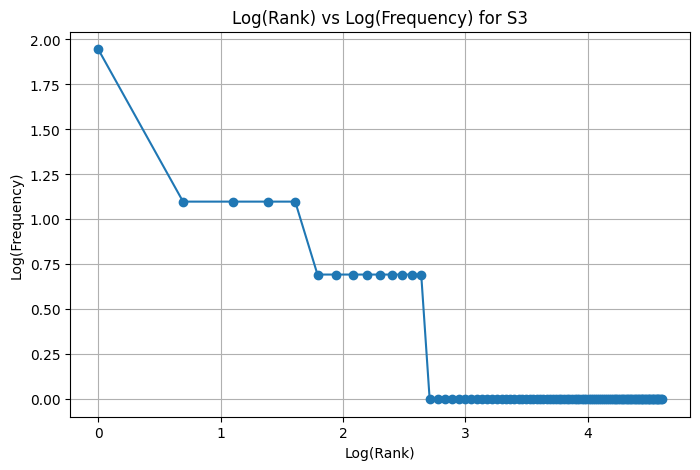

In [ ]:
# Log(Rank) vs Log(Frequency) Plot for S3
S3 = []
for t in processed_tickets:
    S3.extend(t['final_tokens'])

s3_counts = Counter(S3).most_common()
frequencies = [count for word, count in s3_counts]
ranks = list(range(1, len(frequencies) + 1))

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(frequencies), marker='o', linestyle='-')
plt.title('Log(Rank) vs Log(Frequency) for S3')
plt.xlabel('Log(Rank)')
plt.ylabel('Log(Frequency)')
plt.grid(True)
plt.show()

### Question 6: Interpretation Answers

- **(a) Why TTR changes**: TTR decreases from S1 to S4 because preprocessing and stemming progressively normalize different grammatical forms or remove common vocabulary (stopwords/punctuation). This collapses the number of unique words faster than the decrease in total words.
- **(b) Custom Tokenizer vs NLTK**: `word_tokenize()` splits contracted words like "isn't" into `["is", "n't"]` whereas `my_tokenize()` preserves "isn't" as a single cohesive token.
- **(c) Stemming failure**: For example, stemming "flickering" with Lancaster results in "flick", and "frequently" becomes "frequ", losing context or yielding non-standard words.
- **(d) POS-aware lemmatization**: Stemming "complaining" collapses to "complain" blindly, while POS-tagged lemmatization distinguishes between part-of-speech uses to preserve morphology.